**Post-processing baseline.** Fixed best encoder and HistGB parameters, one seed (42), and the same five 80/20 patient-grouped splits as the original notebooks. Each fold independently fits preprocessing and both models; the encoder retains its internal patient holdout for epoch selection and subsequent refit. No parameter search.

Run all cells once to evaluate the model and save validation predictions. Afterwards, the last cell alone can reload the CSV and plot five validation patients against the true corrected OFF target. Change `PLOT_FOLD` to choose a split.


In [1]:
import json
from pathlib import Path

PROJECT_DIR = next(p for p in (Path.cwd(), *Path.cwd().parents)
                   if (p / "exploration/features_selection.ipynb").is_file())
encoder_definitions = json.loads(
    (PROJECT_DIR / "exploration/stacking/histgb_opt.ipynb").read_text()
)
# Setup and function definitions only: no validation, search or final training.
for i in [2, 4, 6, 8, 10]:
    exec("".join(encoder_definitions["cells"][i]["source"]))

# Winning encoder from opt.ipynb (trial 19).
ENCODER = dict(width=32, heads=8, layers=3, dropout=0.1347886862599206,
               ff_multiplier=3, mlp_layers=2, mlp_units=16)
LEARNING_RATE, WEIGHT_DECAY = 0.001759366313629433, 4.3514588969246546e-05
# Winning HistGB from histgb_opt.ipynb.
baseline[-1].set_params(
    learning_rate=0.03471523676107423, max_iter=800, max_leaf_nodes=62,
    min_samples_leaf=16, l2_regularization=8.305016398991823,
    max_features=0.6408427464001498,
)
SEED = 42
PREDICTIONS_PATH = PROJECT_DIR / "data/post_processing_validation_predictions.csv"


Device: mps; baseline: HistGradientBoostingRegressor(l2_regularization=1.8115270802885095,
                              learning_rate=0.042592090635273853,
                              max_features=0.6078232265551354, max_iter=800,
                              max_leaf_nodes=62, min_samples_leaf=25,
                              random_state=42)


In [2]:
cv = GroupShuffleSplit(n_splits=5, test_size=0.2, random_state=SEED)
scores, validation_predictions = [], []
with threadpool_limits(limits=3):
    for fold, (train_idx, val_idx) in enumerate(cv.split(X, y, groups=X["patient_id"]), 1):
        raw_train, raw_val = X.iloc[train_idx], X.iloc[val_idx]
        yt, yv = y.iloc[train_idx], y.iloc[val_idx]
        prep = clone(baseline[:-1])
        train, validation = prep.fit_transform(raw_train, yt), prep.transform(raw_val)
        imputed_train, imputed_val = prep[:2].transform(raw_train), prep[:2].transform(raw_val)
        fitted_encoder = fit_encoder(raw_train, yt, imputed_train, SEED)
        z_train, _ = encoder_outputs(fitted_encoder, raw_train, imputed_train)
        z_val, _ = encoder_outputs(fitted_encoder, raw_val, imputed_val)
        model = clone(baseline[-1]).fit(train.join(z_train), yt)
        prediction = model.predict(validation.join(z_val))
        mse = mean_squared_error(yv, prediction)
        scores.append(dict(fold=fold, epochs=fitted_encoder["epochs"], MSE=mse))
        validation_predictions.append(raw_val[["Index", "patient_id", "age"]].assign(
            fold=fold, target=yv, prediction=prediction
        ))
        print(f"Fold {fold}/5: MSE {mse:.4f}, RMSE {np.sqrt(mse):.4f}")

validation_predictions = pd.concat(validation_predictions, ignore_index=True)
validation_predictions.to_csv(PREDICTIONS_PATH, index=False)
scores = pd.DataFrame(scores)
scores["RMSE"] = np.sqrt(scores["MSE"])
print(f"CV MSE: {scores.MSE.mean():.4f} ± {scores.MSE.std(ddof=0):.4f}; "
      f"RMSE: {np.sqrt(scores.MSE.mean()):.4f}")
scores


Fold 1/5: MSE 7.5462, RMSE 2.7470
Fold 2/5: MSE 7.5201, RMSE 2.7423
Fold 3/5: MSE 6.8763, RMSE 2.6223
Fold 4/5: MSE 6.9775, RMSE 2.6415
Fold 5/5: MSE 7.4933, RMSE 2.7374
CV MSE: 7.2827 ± 0.2927; RMSE: 2.6986


,fold,epochs,MSE,RMSE
0,1,56,7.546179,2.747031
1,2,67,7.520071,2.742275
2,3,86,6.876295,2.622269
3,4,69,6.977544,2.641504
4,5,60,7.493283,2.737386


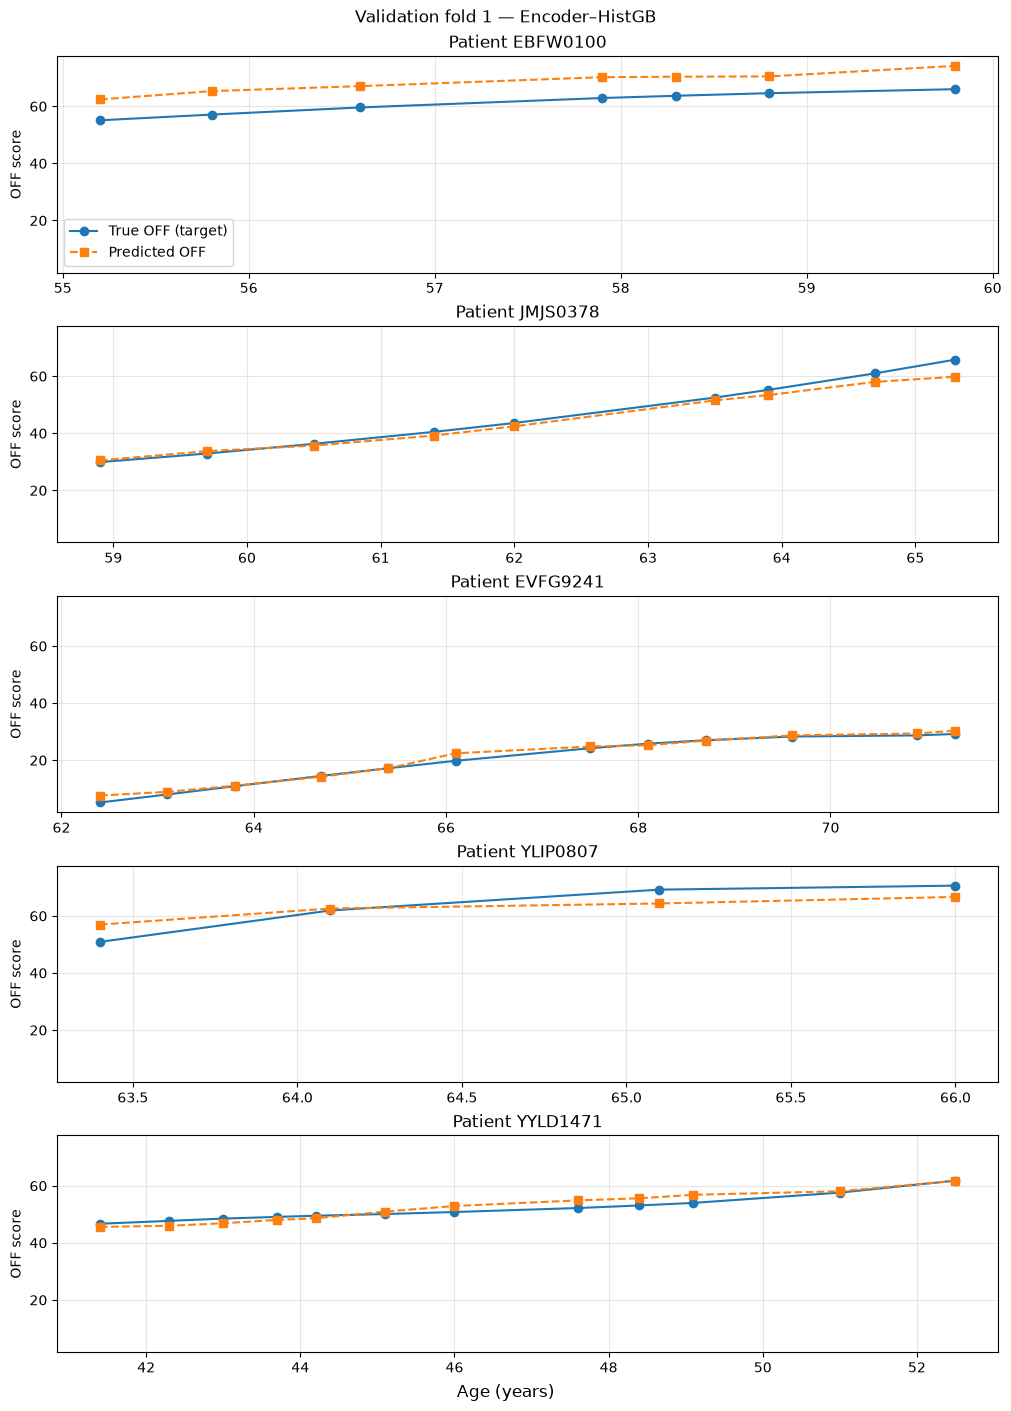

In [3]:
# This cell also runs on its own after a kernel restart, once the CSV exists.
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plot_root = next(p for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / "exploration/features_selection.ipynb").is_file())
plot_data = pd.read_csv(plot_root / "data/post_processing_validation_predictions.csv")
PLOT_FOLD = 1
plot_data = plot_data.loc[plot_data["fold"].eq(PLOT_FOLD)]
patients = plot_data["patient_id"].drop_duplicates().sample(5, random_state=42)

fig, axes = plt.subplots(5, 1, figsize=(10, 14), sharey=True, layout="constrained")
for ax, patient in zip(axes, patients):
    visits = plot_data.loc[plot_data["patient_id"].eq(patient)].sort_values("age")
    ax.plot(visits["age"], visits["target"], "o-", label="True OFF (target)")
    ax.plot(visits["age"], visits["prediction"], "s--", label="Predicted OFF")
    ax.set(title=f"Patient {patient}", ylabel="OFF score")
    ax.grid(alpha=0.3)
axes[0].legend()
fig.suptitle(f"Validation fold {PLOT_FOLD} — Encoder–HistGB")
fig.supxlabel("Age (years)")
plt.show()
